### Import libraries

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

### Load the cleaned dataset

In [3]:
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

df = pd.read_csv(
    ROOT / "datasets/processed/cleaned_paddy.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

### Calculate question and answer lengths

In [4]:
df["question_chars"] = df["question"].str.len()
df["answer_chars"] = df["answer"].str.len()

### Analyze categories by language

In [5]:
print(
    "\nCategory counts:\n",
    df.groupby(["category_en", "language"]).size().unstack(fill_value=0)
)


Category counts:
 language                 en-LK  si-LK
category_en                          
Disease management        1440   1440
Farm operations & costs   1080   1080
Harvest & post-harvest    1320   1320
Land & soil                960    960
Nursery & planting        1080   1080
Nutrients & fertilizer    1080   1080
Pest management           1800   1800
Safety & environment       600    600
Seed & variety             600    600
Water management          1320   1320
Weather & climate          720    720
Weed management            720    720


### Visualize category distribution

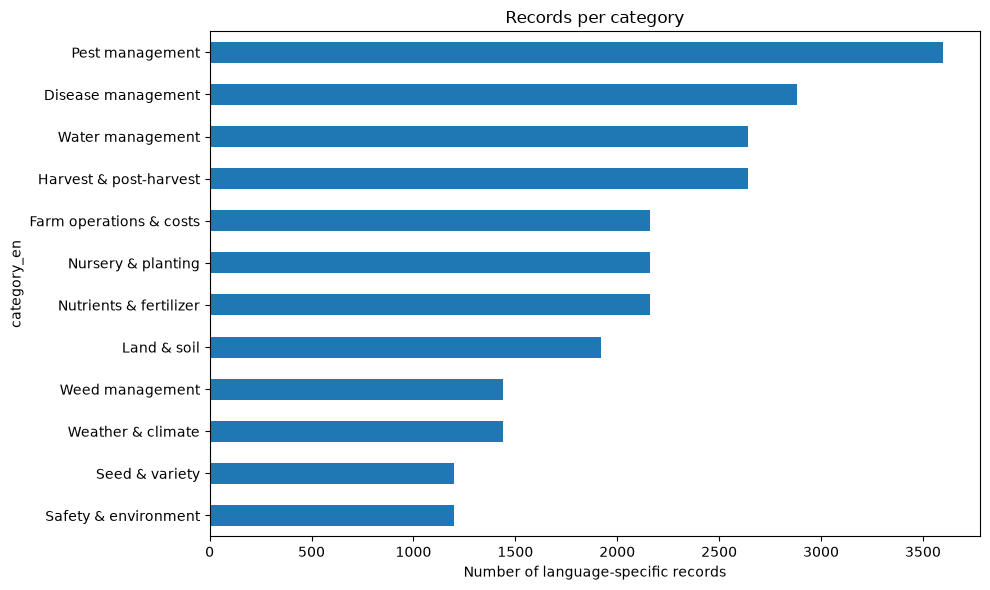

In [6]:
ax = (
    df.groupby("category_en")
    .size()
    .sort_values()
    .plot(
        kind="barh",
        figsize=(10, 6),
        title="Records per category"
    )
)

ax.set_xlabel("Number of language-specific records")

plt.tight_layout()
plt.show()

### Visualize question lengths by language

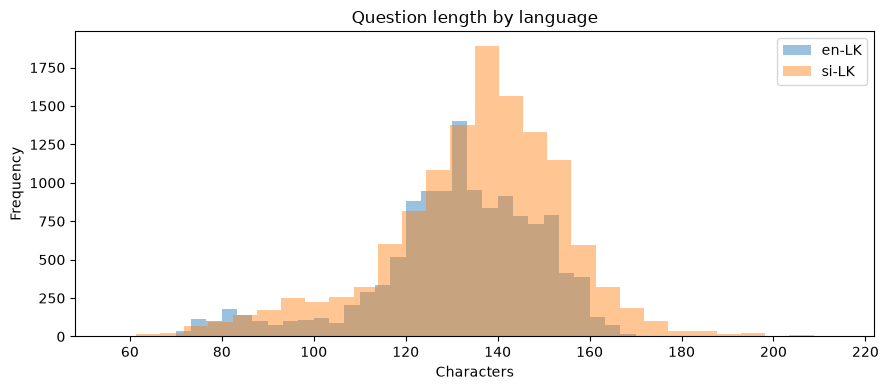

In [7]:
ax = (
    df.groupby("language")["question_chars"]
    .plot(
        kind="hist",
        bins=30,
        alpha=0.45,
        legend=True,
        figsize=(9, 4)
    )
)

plt.title("Question length by language")
plt.xlabel("Characters")
plt.tight_layout()
plt.show()

In [8]:
print("Exact duplicate question rows by language:")

print(
    df.groupby("language")["question"]
    .apply(lambda x: int(x.duplicated().sum()))
)

Exact duplicate question rows by language:
language
en-LK    6360
si-LK       0
Name: question, dtype: int64
